In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project
project_dir = Path.home() / "Electives" / "South_african_weather_pipeline"

# Load the processed weather data
csv_path = project_dir / "data" / "processed" / "weather.csv"

df = pd.read_csv(csv_path)

# Display the first five records
display(df.head())

print("Total records:", len(df))
print("Unique cities:", df["city"].nunique())

,city,timestamp,temperature_c,humidity_percent,wind_speed_kmh
0,cape_town,2026-10-14T08:45,16.6,58,17.1
1,bloemfontein,2026-10-08T11:15,27.0,35,18.4
2,east_london,2026-10-14T10:30,28.6,71,16.6
3,pretoria,2026-10-08T11:15,27.4,33,8.9
4,east_london,2026-10-14T10:15,28.7,70,16.3


Total records: 79
Unique cities: 9


In [23]:
# Check the dataset's columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   city              79 non-null     str    
 1   timestamp         79 non-null     str    
 2   temperature_c     79 non-null     float64
 3   humidity_percent  79 non-null     int64  
 4   wind_speed_kmh    79 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 3.2 KB


In [24]:
# Check for missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check for duplicate city and timestamp combinations
print(
    "Duplicate city-timestamp records:",
    df.duplicated(subset=["city", "timestamp"]).sum()
)

Missing values:
city                0
timestamp           0
temperature_c       0
humidity_percent    0
wind_speed_kmh      0
dtype: int64

Duplicate rows: 0
Duplicate city-timestamp records: 0


In [25]:
# Calculate average weather conditions for each city
city_summary = df.groupby("city").agg(
    average_temperature=("temperature_c", "mean"),
    average_humidity=("humidity_percent", "mean"),
    average_wind_speed=("wind_speed_kmh", "mean"),
    total_records=("timestamp", "count")
).reset_index()

# Round the averages to two decimal places
city_summary = city_summary.round(2)

# Display the results
display(city_summary)

,city,average_temperature,average_humidity,average_wind_speed,total_records
0,bloemfontein,22.33,52.22,13.68,9
1,cape_town,16.98,57.62,17.29,8
2,durban,26.68,63.00,15.70,9
3,east_london,27.55,68.00,12.91,8
4,gqeberha,23.19,72.33,13.70,9
5,johannesburg,24.30,37.11,12.63,9
6,mbombela,26.54,58.56,9.87,9
7,polokwane,25.58,41.89,18.23,9
8,pretoria,27.50,30.56,11.64,9


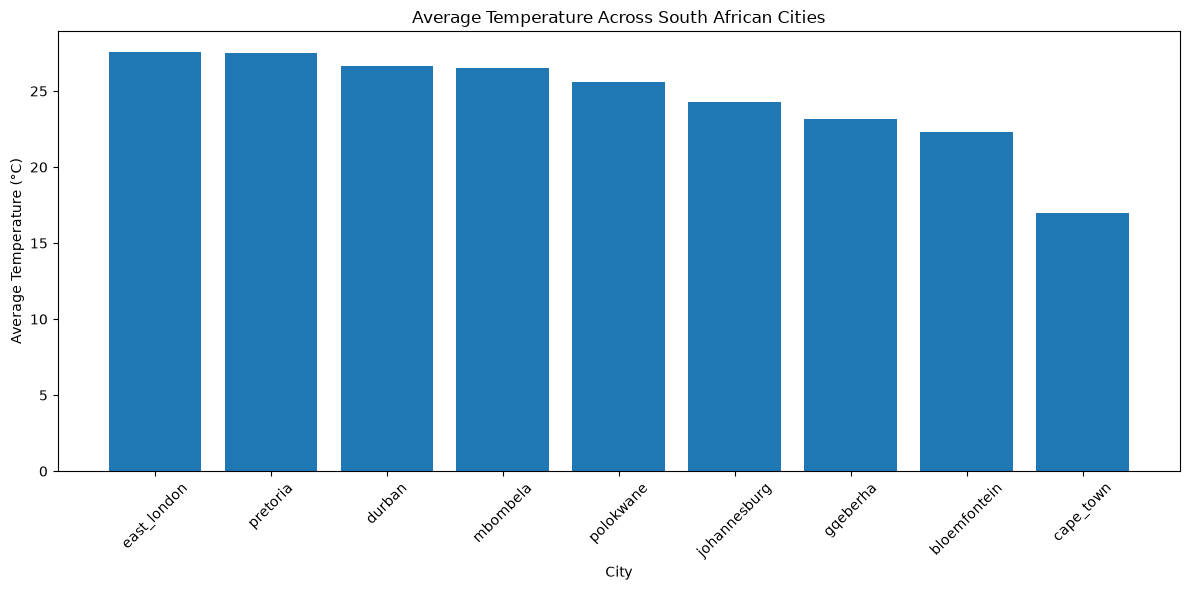

In [26]:
# Sort cities from warmest to coolest
temperature_summary = city_summary.sort_values(
    by="average_temperature",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    temperature_summary["city"],
    temperature_summary["average_temperature"]
)

plt.title("Average Temperature Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [27]:
### Temperature Analysis

The collected weather readings show differences in average
temperature across the nine South African cities.

East London recorded the highest average temperature at 27.55°C,
while Cape Town recorded the lowest at 16.98°C.

This comparison provides an overview of the temperatures recorded
by the pipeline during the collection period. The averages should
not be interpreted as long-term climate averages.

SyntaxError: invalid character '°' (U+00B0) (2040456070.py, line 6)

# Sort cities from highest to lowest average humidity
humidity_summary = city_summary.sort_values(
    by="average_humidity",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    humidity_summary["city"],
    humidity_summary["average_humidity"]
)

plt.title("Average Humidity Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
### Humidity Analysis

The collected weather readings show differences in average
humidity across the nine South African cities.

Gqeberha recorded the highest average humidity at 72.33%,
while Pretoria recorded the lowest at 30.56%.

These results describe the readings collected during the
observation period and do not represent long-term climate averages.

In [ ]:
# Sort cities from highest to lowest average wind speed
wind_summary = city_summary.sort_values(
    by="average_wind_speed",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    wind_summary["city"],
    wind_summary["average_wind_speed"]
)

plt.title("Average Wind Speed Across South African Cities")
plt.xlabel("City")
plt.ylabel("Average Wind Speed (km/h)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
### Wind Speed Analysis

The collected weather readings show differences in average wind
speed across the nine South African cities.

Polokwane recorded the highest average wind speed at 18.23 km/h,
while Mbombela recorded the lowest at 9.87 km/h.

These results describe the readings collected during the observation
period and should not be interpreted as long-term climate averages.

# Conclusion

This project developed a weather data pipeline to collect,
transform, validate, and store weather data for nine South African cities.

The processed dataset contains 79 weather records across nine cities.
Data quality checks confirmed that there were no missing values,
duplicate rows, or duplicate city-timestamp combinations.

The analysis compared average temperature, humidity, and wind speed
across the selected cities. Three bar charts were created to visualise
the differences in recorded weather conditions.

East London recorded the highest average temperature, while Cape Town
recorded the lowest. Gqeberha had the highest average humidity, and
Polokwane had the highest average wind speed.

These findings describe the collected observations rather than
long-term climate patterns. Since readings may have been collected
at different times, the averages do not necessarily represent
weather conditions at the same moment.

The project demonstrates practical skills in Python, pandas, data
validation, data pipelines, SQLite, testing, and data visualisation.